# 037 — SVM linear

Preparação central original. Fit apenas no treino de cada divisão. Seleção interna/CV dentro das 8.769 linhas; validação fixa de desenvolvimento com 2.193 linhas. Sem submissão automática.

Resultado real guardado; não foi iniciado novo treino.
Kaggle: por submeter
Configuração selecionada: {'params': {'C': 0.01, 'class_weight': 'balanced', 'max_iter': 10000}, 'label': 'C=0.01, class_weight=balanced', 'cv_macro_f1': [0.408795574131913, 0.419282167665054, 0.42106952913706935], 'cv_macro_f1_mean': 0.41638242364467876, 'cv_macro_f1_std': 0.0066309033626593605, 'cv_accuracy_mean': 0.4255901471091345, 'cv_train_macro_f1_mean': 0.7896202732353371}
CSV: {'path': 'submissions/submission_037_novo_modelo.csv', 'differences': {'submission_001_regressao_logistica(1).csv': 966, 'submission_002_regressao_logistica_regularizada.csv': 636, 'submission_004_arvore_decisao.csv': 2271, 'submission_012_mlp_perda_ponderada.csv': 1542, 'submission_013_mlp_arquitetura.csv': 1542, 'submission_014_xgboost_mlp.csv': 1288, 'submission_015_mlp_learning_rate.csv': 1149, 'submission_028_ensemble_features_dominio.csv': 1276, 'submission_029_catboost.csv': 1517, 'submission_031_catboost_ponderacao_suave.

,parcela,Macro F1,accuracy
0,train,0.733732,0.717300
1,validation,0.395200,0.399453


,classe,escalão,F1,recall,support
0,0,15–17 anos,0.690476,0.707317,41
1,1,18–19 anos,0.311688,0.352941,34
2,2,20–24 anos,0.477987,0.475000,80
3,3,25–29 anos,0.348837,0.400000,75
4,4,30–34 anos,0.234742,0.277778,90
5,5,35–39 anos,0.271062,0.286822,129
6,6,40–44 anos,0.257353,0.203488,172
7,7,45–49 anos,0.338762,0.300578,173
8,8,50–54 anos,0.593909,0.646409,181
9,9,55–59 anos,0.573427,0.605911,203


,params,label,cv_macro_f1,cv_macro_f1_mean,cv_macro_f1_std,cv_accuracy_mean,cv_train_macro_f1_mean
0,"{'C': 0.01, 'class_weight': None, 'max_iter': ...","C=0.01, class_weight=None","[0.4007093224018933, 0.4187575951028957, 0.421...",0.413554,0.011190,0.428555,0.787909
1,"{'C': 0.01, 'class_weight': 'balanced', 'max_i...","C=0.01, class_weight=balanced","[0.408795574131913, 0.419282167665054, 0.42106...",0.416382,0.006631,0.425590,0.789620
2,"{'C': 0.1, 'class_weight': None, 'max_iter': 1...","C=0.1, class_weight=None","[0.38562831097914313, 0.39313675194284836, 0.4...",0.395468,0.011188,0.401072,0.925956
3,"{'C': 0.1, 'class_weight': 'balanced', 'max_it...","C=0.1, class_weight=balanced","[0.38211743005013943, 0.3883039875363207, 0.40...",0.392055,0.012251,0.396853,0.921055
4,"{'C': 1.0, 'class_weight': None, 'max_iter': 1...","C=1.0, class_weight=None","[0.36500168392276233, 0.35562634917440883, 0.3...",0.364063,0.008009,0.368343,0.988085
5,"{'C': 1.0, 'class_weight': 'balanced', 'max_it...","C=1.0, class_weight=balanced","[0.36486269674369626, 0.35911436641770134, 0.3...",0.365412,0.006590,0.369027,0.985993


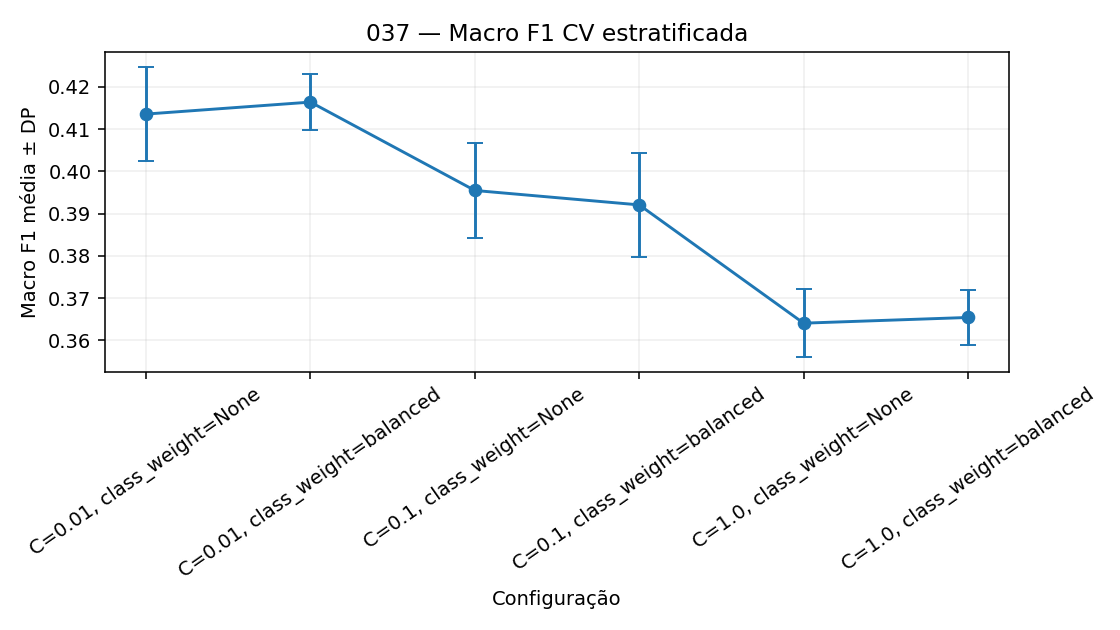

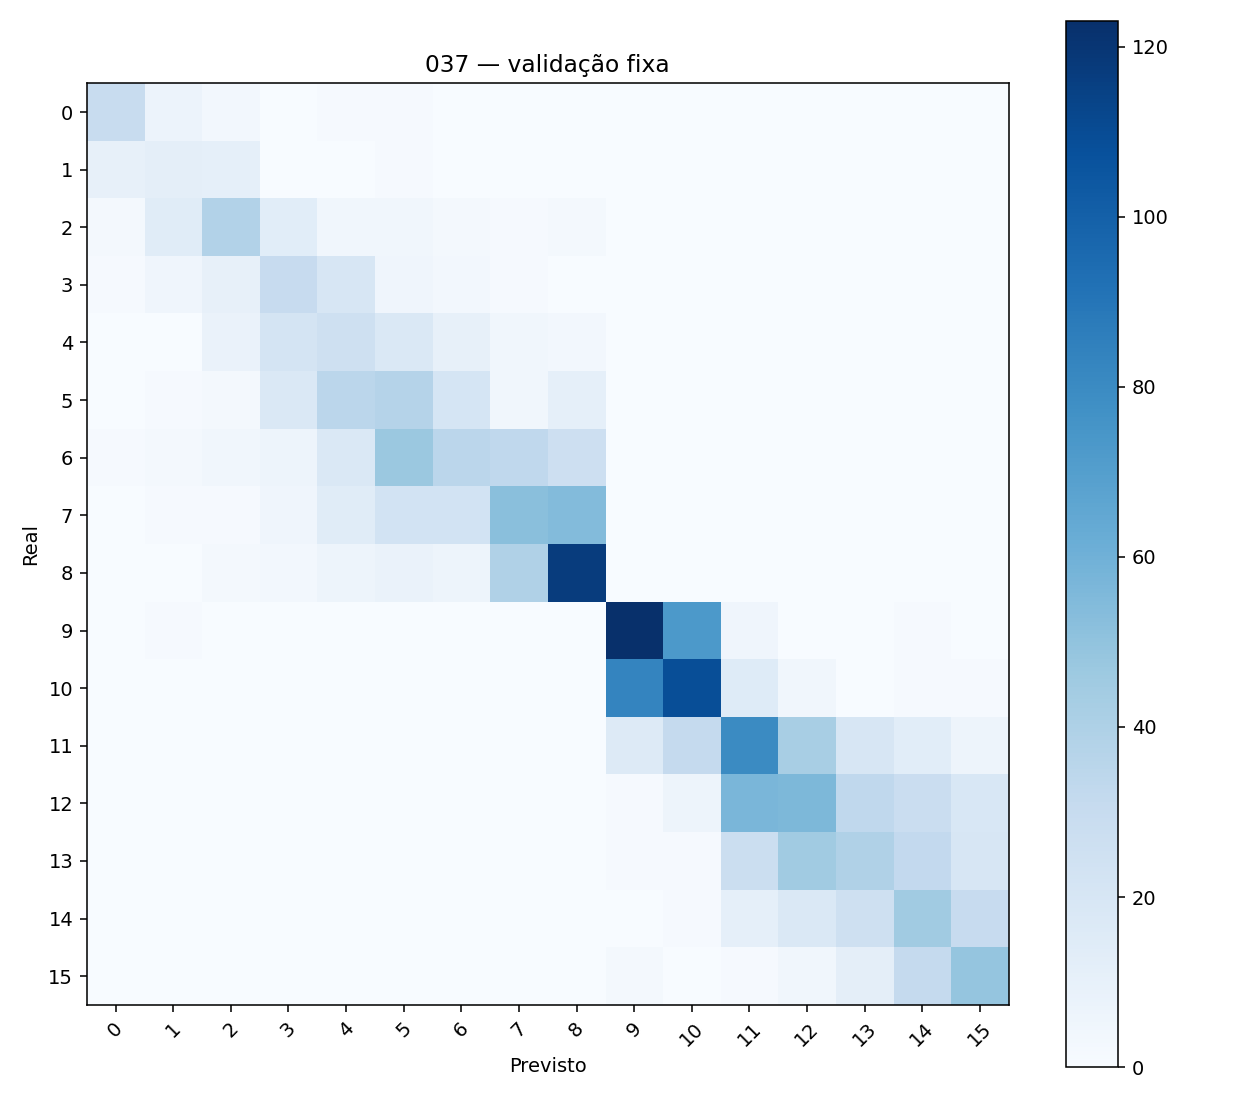

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image
root = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / 'src/ver_resultados.py').is_file())
sys.path.insert(0, str(root))
from src.ver_resultados import carregar_resultado
result = carregar_resultado('037')
print('Resultado real guardado; não foi iniciado novo treino.')
print('Kaggle: por submeter')
selected = result.get('selected_internally', result.get('selected'))
if isinstance(selected, dict): selected = {k:v for k,v in selected.items() if k not in ['history', 'ae', 'folds']}
print('Configuração selecionada:', selected)
metrics = result.get('fixed_metrics', result.get('metrics', {}))
if metrics:
    display(pd.DataFrame([{'parcela':k, 'Macro F1':m['macro_f1'], 'accuracy':m['accuracy']} for k,m in metrics.items() if isinstance(m,dict) and 'macro_f1' in m]))
    if 'validation' in metrics:
        detail = metrics['validation'].get('per_class', metrics['validation'].get('classification_report', {}))
        if detail: display(pd.DataFrame(detail))
rows = result.get('candidates', result.get('results', []))
if rows:
    display(pd.DataFrame([{k:v for k,v in r.items() if k not in ['history','ae','folds','age_profile_posthoc','sizes']} for r in rows]))
images = list((root/'reports').glob('experiencia_037_*.png')) + list((root/'reports').glob('037*.png'))
for p in sorted(set(images)): display(Image(filename=str(p)))
print('CSV:', result.get('submission'))
print('Notas:', result.get('note', ''))


## Conclusões
- Data: 16/11
- Macro F1 de desenvolvimento: **0.3952**; accuracy: **0.3995**. Abaixo da referência histórica 025 (0,4615); não demonstra uma melhoria global.
- Pontuação Kaggle: 0.43
- Conclusão: sem superar a regressão logística ou os melhores ensembles. O desfasamento treino/validação sugere sobreajustamento.
- Melhorias: Testar seleção de características e categorias raras agrupadas dentro dos folds. Baixa prioridade para nova afinação.